# B5 — Integrasi: Rangkaian Praproses SIMUTEH

Evaluasi Praktikum P1–P4 Computer Vision
SIMUTEH — Klasifikasi Kualitas Daun Teh

In [1]:
   import sys, os, time
   import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
   sys.path.append("../src")
   from utils_cv import baca, tampil, kontras_bercak, statistik

   DATA_DIR = "../data/sintetis"
   HASIL_DIR = "../hasil"
   os.makedirs(HASIL_DIR, exist_ok=True)

# 5.2 Evaluasi Kuantitatif

In [2]:
# Evaluasi Kuantitatif Rangkaian Praproses
from praproses import praproses, simpan_param

# Parameter praproses
param = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0
}

# Simpan parameter ke JSON
simpan_param(param, os.path.join(HASIL_DIR, "param_praproses.json"))

# Kanal BGR: 0 = B, 1 = G, 2 = R
# Sesuaikan dengan kanal terbaik dari hasil B2
KANAL = 2

label = pd.read_csv(os.path.join(DATA_DIR, "label.csv"))

baris = []

# Menguji seluruh 40 citra berbercak
for _, d in label[label.kelas != "sehat"].iterrows():

    nm = d["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)
    mb = cv2.imread(os.path.join(DATA_DIR, "mask_bercak", nm), 0)

    if img is None or md is None or mb is None:
        print("Citra atau mask tidak ditemukan:", nm)
        continue

    # Proses praproses
    out = praproses(img, param)

    # Sesuaikan ukuran mask dengan hasil praproses
    ukuran = (out.shape[1], out.shape[0])
    md_out = cv2.resize(md, ukuran, interpolation=cv2.INTER_NEAREST)
    mb_out = cv2.resize(mb, ukuran, interpolation=cv2.INTER_NEAREST)

    # Hitung KB sebelum dan sesudah
    kb_sebelum = kontras_bercak(img[:, :, KANAL], md, mb)
    kb_sesudah = kontras_bercak(out[:, :, KANAL], md_out, mb_out)

    baris.append([
        d["kondisi_cahaya"],
        nm,
        kb_sebelum,
        kb_sesudah
    ])

evaluasi = pd.DataFrame(
    baris,
    columns=["kondisi", "nama_file", "KB_sebelum", "KB_sesudah"]
)

# Rata-rata KB berdasarkan kondisi cahaya
ringkasan = evaluasi.groupby("kondisi")[
    ["KB_sebelum", "KB_sesudah"]
].mean()

ringkasan["Perubahan (%)"] = (
    (ringkasan["KB_sesudah"] - ringkasan["KB_sebelum"])
    / ringkasan["KB_sebelum"] * 100
)

print("HASIL EVALUASI RANGKAIAN PRAPROSES")
display(ringkasan.round(2))

print("Jumlah citra yang berhasil diuji:", len(evaluasi))

# Simpan hasil evaluasi
evaluasi.to_csv(
    os.path.join(HASIL_DIR, "b5_evaluasi_praproses.csv"),
    index=False
)

ringkasan.round(2).to_csv(
    os.path.join(HASIL_DIR, "b5_tabel12.csv")
)

HASIL EVALUASI RANGKAIAN PRAPROSES


,KB_sebelum,KB_sesudah,Perubahan (%)
kondisi,,,
bayangan,4.09,7.50,83.22
gelap,9.52,15.89,66.88
kontras_rendah,3.97,4.98,25.34
normal,8.84,10.15,14.88
terang,6.53,5.83,-10.78


Jumlah citra yang berhasil diuji: 40


# 5.3 Uji Bercak Palsu pada Kelas Sehat

UJI BERCAK PALSU: RERATA SIMPANGAN BAKU KANAL R PADA AREA DAUN (20 citra sehat)


,std_sebelum,std_sesudah,perubahan (%)
kondisi,,,
normal,9.82,8.40,-14.42
gelap,9.42,6.69,-28.90
terang,11.87,12.77,7.61
kontras_rendah,10.30,10.00,-2.86
bayangan,15.36,11.03,-28.15


Jumlah citra: 20
Kondisi dengan keragaman daun sehat NAIK setelah praproses: ['terang']


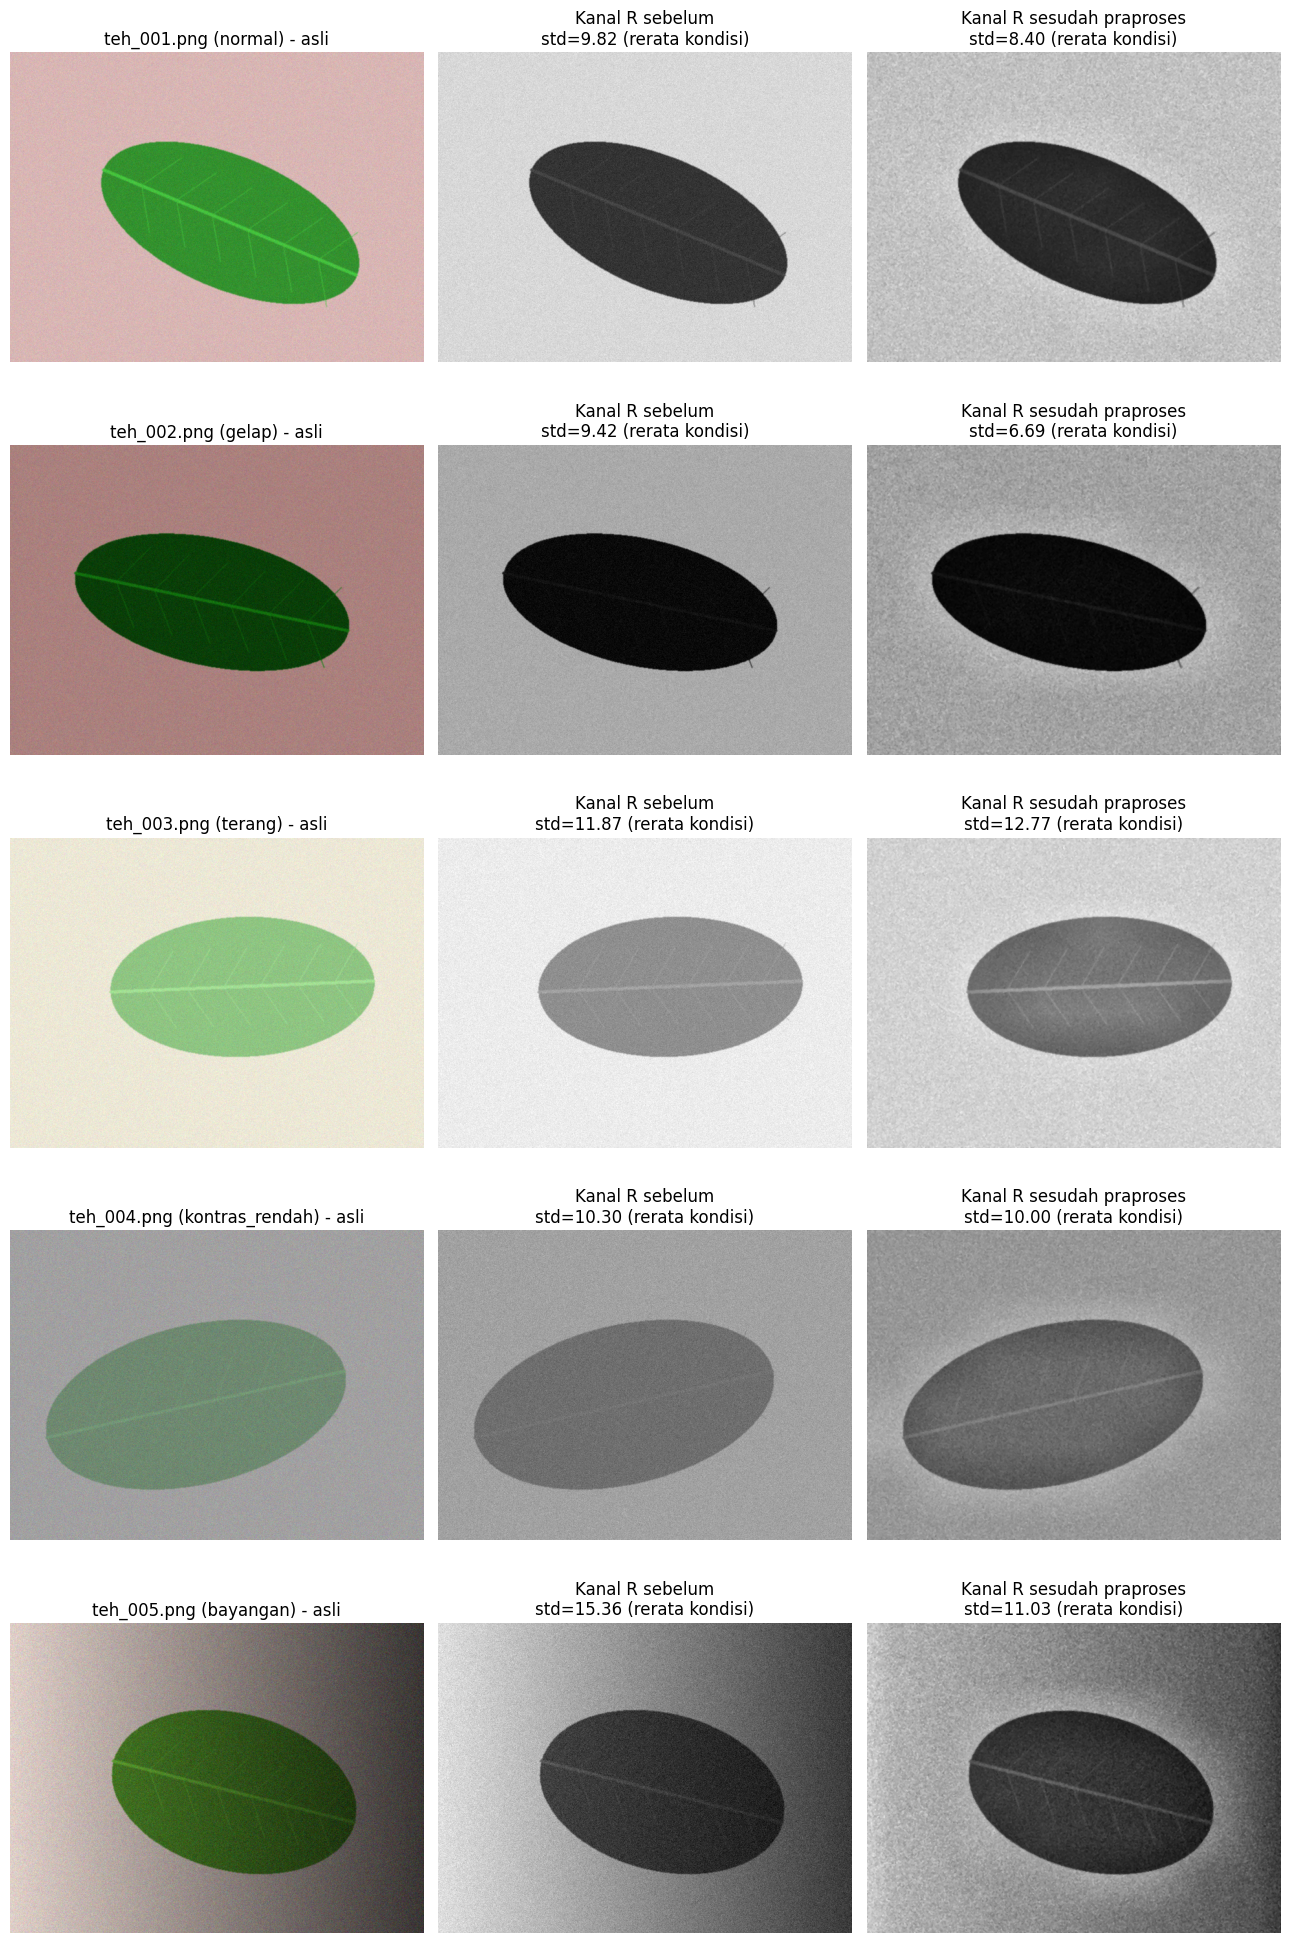

In [3]:
# Uji Bercak Palsu pada Kelas Sehat
baris_sehat = []

# Mengambil 20 citra kelas sehat
data_sehat = label[label["kelas"] == "sehat"].head(20)

for _, d in data_sehat.iterrows():

    nm = d["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    md = cv2.imread(os.path.join(DATA_DIR, "mask_daun", nm), 0)

    out = praproses(img, param)

    # Sesuaikan mask dengan ukuran hasil praproses
    md_out = cv2.resize(
        md,
        (out.shape[1], out.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    # Simpangan baku kanal terpilih pada area daun
    std_sebelum = img[:, :, KANAL][md > 0].std()
    std_sesudah = out[:, :, KANAL][md_out > 0].std()

    baris_sehat.append([
        nm,
        d["kondisi_cahaya"],
        std_sebelum,
        std_sesudah
    ])

hasil_sehat = pd.DataFrame(
    baris_sehat,
    columns=["nama_file", "kondisi", "std_sebelum", "std_sesudah"]
)

# Rerata per kondisi, urut sesuai petunjuk
urutan_kondisi = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]

ringkas_sehat = (
    hasil_sehat.groupby("kondisi")[["std_sebelum", "std_sesudah"]]
    .mean()
    .reindex(urutan_kondisi)
)
ringkas_sehat["perubahan (%)"] = (
    100 * (ringkas_sehat["std_sesudah"] - ringkas_sehat["std_sebelum"])
    / ringkas_sehat["std_sebelum"]
)
ringkas_sehat = ringkas_sehat.round(2)

print("UJI BERCAK PALSU: RERATA SIMPANGAN BAKU KANAL R PADA AREA DAUN (20 citra sehat)")
display(ringkas_sehat)
print("Jumlah citra:", len(hasil_sehat))

naik = ringkas_sehat[ringkas_sehat["perubahan (%)"] > 0].index.tolist()
print("Kondisi dengan keragaman daun sehat NAIK setelah praproses:", naik)

hasil_sehat.round(2).to_csv(
    os.path.join(HASIL_DIR, "b5_uji_bercak_palsu.csv"),
    index=False
)
ringkas_sehat.to_csv(os.path.join(HASIL_DIR, "b5_uji_bercak_palsu_ringkas.csv"))

# Panel: satu citra sehat per kondisi -> citra asli, kanal R sebelum, kanal R sesudah
fig, axes = plt.subplots(len(urutan_kondisi), 3, figsize=(13, 4 * len(urutan_kondisi)))

for i, kondisi in enumerate(urutan_kondisi):

    nm = hasil_sehat[hasil_sehat["kondisi"] == kondisi].iloc[0]["nama_file"]

    img = cv2.imread(os.path.join(DATA_DIR, "citra", nm))
    out = praproses(img, param)

    axes[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i, 0].set_title(f"{nm} ({kondisi}) - asli")

    axes[i, 1].imshow(img[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"Kanal R sebelum\nstd={ringkas_sehat.loc[kondisi, 'std_sebelum']:.2f} (rerata kondisi)")

    axes[i, 2].imshow(out[:, :, KANAL], cmap="gray", vmin=0, vmax=255)
    axes[i, 2].set_title(f"Kanal R sesudah praproses\nstd={ringkas_sehat.loc[kondisi, 'std_sesudah']:.2f} (rerata kondisi)")

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(HASIL_DIR, "b5_panel_bercak_palsu.png"), dpi=150, bbox_inches="tight")
plt.show()

# 5.4 Justifikasi

In [4]:
# B5.4 - Tabel 13: Justifikasi Rangkaian Praproses
# Rujukan nama file di bawah nanti diganti nomor Tabel/Gambar di laporan.

tabel13 = pd.DataFrame([
    [
        "1. Ubah ukuran",
        "lebar = 640 px, INTER_AREA",
        "Mengikuti kebutuhan pengguna no. 4 (cepat di HP kelas menengah). "
        "Lembar hitung 2.1 d): pada lebar 640 px bercak 5 mm hanya 7,62 px saat Z = 300 mm, "
        "sehingga jarak potret harus <= 228,57 mm agar bercak >= 10 px. "
        "Eksperimen sampling (b2_tabel_sampling.csv, b2_sampling.png) menunjukkan detail bercak "
        "mulai hilang bila citra diperkecil lebih jauh.",
        "Terlalu kecil: bercak ringan hilang (P2.5). Terlalu besar: waktu proses naik kuadratik (P4.6)."
    ],
    [
        "2. Koreksi gamma",
        "gamma = 1,0 (tidak dipakai)",
        "Satu nilai gamma tetap tidak cocok untuk semua kondisi, dan arah koreksi yang tampak benar "
        "secara visual belum tentu menaikkan KB: pada kondisi gelap gamma 0,5 justru menurunkan KB "
        "(teh_042: 5,19 -> 4,19), sedangkan gamma 1,8 menaikkannya (7,13) (b3_5_kb_kandidat.csv, "
        "b3_4kondisi.png). Tanpa gamma pun KB kondisi gelap sudah naik 66,88% berkat CLAHE kanal V "
        "(b5_tabel12.csv).",
        "Gamma tetap yang salah arah merusak satu kondisi; gamma < 1 juga mengangkat bercak pucat "
        "sehingga selisihnya dengan daun mengecil."
    ],
    [
        "3. CLAHE kanal V",
        "clip = 2,0, tile = 8x8",
        "Pada citra bayangan, ekualisasi global menurunkan KB (2,45 -> 1,83) sedangkan CLAHE "
        "menaikkannya (2,55) (b3_tabel10.csv, b3_asli_ekualisasi_clahe.png). Diterapkan di kanal V "
        "agar rona warna tidak bergeser (b3_clahe_v_vs_bgr.csv). Hasil rangkaian: KB bayangan naik "
        "83,22% (b5_tabel12.csv). Catatan: pada teh_045, KB tertinggi justru clip 1,0 tile 4x4 "
        "(3,18; b3_4_matriks_clahe.csv); nilai 2,0/8x8 dipertahankan sebagai nilai bawaan dan "
        "pengujian clip lebih rendah pada seluruh 40 citra menjadi rencana perbaikan.",
        "Clip terlalu tinggi memperkuat derau; terbukti pada kondisi terang KB turun 10,78% dan "
        "simpangan baku daun sehat naik 7,61% (b5_uji_bercak_palsu_ringkas.csv)."
    ],
    [
        "4. Redam derau",
        "median, kernel 3x3",
        "Trade-off antara meredam derau dan menjaga bercak kecil. Pada kelas ringan, dI tetap terjaga "
        "pada kernel 3 (28,08) tetapi turun pada kernel 9 (21,14) dan 15 (8,35) "
        "(b4_pengaruh_kernel_median.csv, b4_dI_kernel.png, b4_crop_bercak.png). Median paling tahan "
        "derau garam-merica (median 3 pada sp 4%: 47,98 dB; b4_tabel11.csv). Pada derau sensor bawaan, "
        "median 3 menaikkan PSNR 32,39 -> 39,44 dB; median 5 (41,61 dB) dan Gaussian 5 (40,80 dB) "
        "lebih tinggi, tetapi kernel kecil dipilih untuk mengutamakan bercak kecil "
        "(b4_ringkasan_derau_sensor.csv).",
        "Kernel terlalu besar menghapus bercak kecil sehingga daun bercak ringan bisa dinilai sehat."
    ],
    [
        "5. Tajamkan",
        "tajam_k = 0 (tidak dipakai)",
        "Penajaman memperkuat derau sehingga simpangan baku latar naik dan PSNR turun "
        "(b4_urutan_tajam.csv, b4_urutan_tajam.png). Sasaran SIMUTEH adalah warna dan intensitas "
        "bercak, bukan tepi, sehingga penajaman tidak memberi manfaat yang sebanding dengan risikonya.",
        "Penajaman berlebih membuat butiran derau tampak seperti bercak kecil (bercak palsu)."
    ],
], columns=[
    "Langkah",
    "Parameter final",
    "Alasan dan bukti (rujuk tabel atau gambar)",
    "Risiko bila salah atur",
])

pd.set_option("display.max_colwidth", None)
display(tabel13)

tabel13.to_csv(
    os.path.join(HASIL_DIR, "b5_tabel13_justifikasi.csv"),
    index=False
)

,Langkah,Parameter final,Alasan dan bukti (rujuk tabel atau gambar),Risiko bila salah atur
0,1. Ubah ukuran,"lebar = 640 px, INTER_AREA","Mengikuti kebutuhan pengguna no. 4 (cepat di HP kelas menengah). Lembar hitung 2.1 d): pada lebar 640 px bercak 5 mm hanya 7,62 px saat Z = 300 mm, sehingga jarak potret harus <= 228,57 mm agar bercak >= 10 px. Eksperimen sampling (b2_tabel_sampling.csv, b2_sampling.png) menunjukkan detail bercak mulai hilang bila citra diperkecil lebih jauh.",Terlalu kecil: bercak ringan hilang (P2.5). Terlalu besar: waktu proses naik kuadratik (P4.6).
1,2. Koreksi gamma,"gamma = 1,0 (tidak dipakai)","Satu nilai gamma tetap tidak cocok untuk semua kondisi, dan arah koreksi yang tampak benar secara visual belum tentu menaikkan KB: pada kondisi gelap gamma 0,5 justru menurunkan KB (teh_042: 5,19 -> 4,19), sedangkan gamma 1,8 menaikkannya (7,13) (b3_5_kb_kandidat.csv, b3_4kondisi.png). Tanpa gamma pun KB kondisi gelap sudah naik 66,88% berkat CLAHE kanal V (b5_tabel12.csv).",Gamma tetap yang salah arah merusak satu kondisi; gamma < 1 juga mengangkat bercak pucat sehingga selisihnya dengan daun mengecil.
2,3. CLAHE kanal V,"clip = 2,0, tile = 8x8","Pada citra bayangan, ekualisasi global menurunkan KB (2,45 -> 1,83) sedangkan CLAHE menaikkannya (2,55) (b3_tabel10.csv, b3_asli_ekualisasi_clahe.png). Diterapkan di kanal V agar rona warna tidak bergeser (b3_clahe_v_vs_bgr.csv). Hasil rangkaian: KB bayangan naik 83,22% (b5_tabel12.csv). Catatan: pada teh_045, KB tertinggi justru clip 1,0 tile 4x4 (3,18; b3_4_matriks_clahe.csv); nilai 2,0/8x8 dipertahankan sebagai nilai bawaan dan pengujian clip lebih rendah pada seluruh 40 citra menjadi rencana perbaikan.","Clip terlalu tinggi memperkuat derau; terbukti pada kondisi terang KB turun 10,78% dan simpangan baku daun sehat naik 7,61% (b5_uji_bercak_palsu_ringkas.csv)."
3,4. Redam derau,"median, kernel 3x3","Trade-off antara meredam derau dan menjaga bercak kecil. Pada kelas ringan, dI tetap terjaga pada kernel 3 (28,08) tetapi turun pada kernel 9 (21,14) dan 15 (8,35) (b4_pengaruh_kernel_median.csv, b4_dI_kernel.png, b4_crop_bercak.png). Median paling tahan derau garam-merica (median 3 pada sp 4%: 47,98 dB; b4_tabel11.csv). Pada derau sensor bawaan, median 3 menaikkan PSNR 32,39 -> 39,44 dB; median 5 (41,61 dB) dan Gaussian 5 (40,80 dB) lebih tinggi, tetapi kernel kecil dipilih untuk mengutamakan bercak kecil (b4_ringkasan_derau_sensor.csv).",Kernel terlalu besar menghapus bercak kecil sehingga daun bercak ringan bisa dinilai sehat.
4,5. Tajamkan,tajam_k = 0 (tidak dipakai),"Penajaman memperkuat derau sehingga simpangan baku latar naik dan PSNR turun (b4_urutan_tajam.csv, b4_urutan_tajam.png). Sasaran SIMUTEH adalah warna dan intensitas bercak, bukan tepi, sehingga penajaman tidak memberi manfaat yang sebanding dengan risikonya.",Penajaman berlebih membuat butiran derau tampak seperti bercak kecil (bercak palsu).


# 5.4 Diagram Pipeline

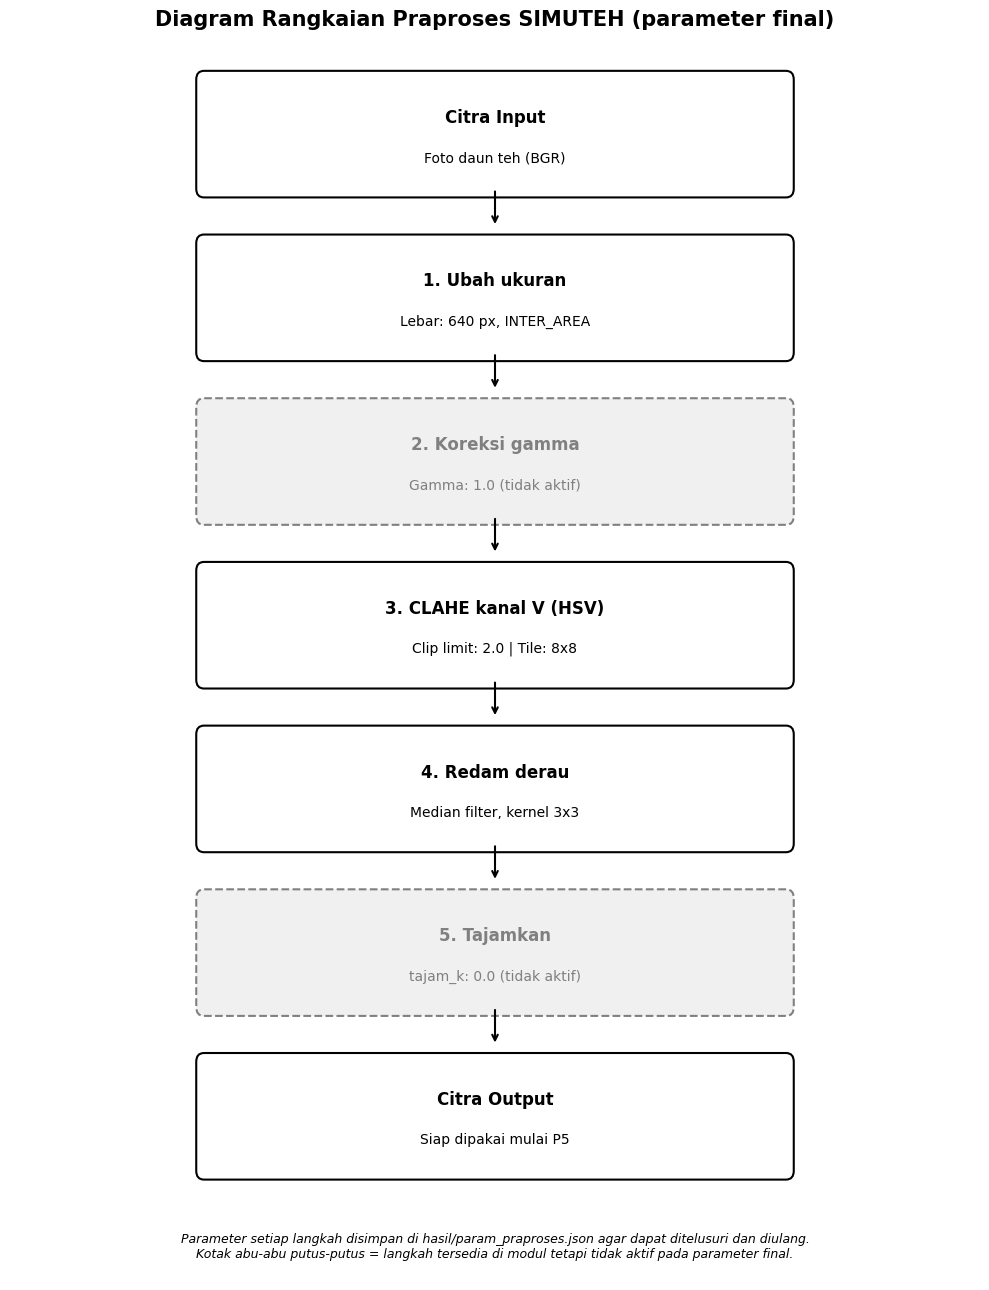

In [5]:
# B5.4 - Diagram Pipeline Praproses SIMUTEH
from matplotlib.patches import FancyBboxPatch

# (judul, detail, aktif?)
tahapan = [
    ("Citra Input", "Foto daun teh (BGR)", True),
    ("1. Ubah ukuran", "Lebar: 640 px, INTER_AREA", True),
    ("2. Koreksi gamma", "Gamma: 1.0 (tidak aktif)", False),
    ("3. CLAHE kanal V (HSV)", "Clip limit: 2.0 | Tile: 8x8", True),
    ("4. Redam derau", "Median filter, kernel 3x3", True),
    ("5. Tajamkan", "tajam_k: 0.0 (tidak aktif)", False),
    ("Citra Output", "Siap dipakai mulai P5", True),
]

fig, ax = plt.subplots(figsize=(10, 13))
ax.set_xlim(0, 10)
ax.set_ylim(-0.8, len(tahapan) * 1.5)
ax.axis("off")

for i, (judul, detail, aktif) in enumerate(tahapan):
    y = len(tahapan) * 1.5 - (i + 1) * 1.5 + 0.2

    kotak = FancyBboxPatch(
        (2, y), 6, 1.0,
        boxstyle="round,pad=0.08",
        edgecolor="black" if aktif else "gray",
        facecolor="white" if aktif else "#f0f0f0",
        linewidth=1.5,
        linestyle="-" if aktif else "--"
    )
    ax.add_patch(kotak)

    warna_teks = "black" if aktif else "gray"
    ax.text(5, y + 0.65, judul, ha="center", va="center",
            fontsize=12, fontweight="bold", color=warna_teks)
    ax.text(5, y + 0.28, detail, ha="center", va="center",
            fontsize=10, color=warna_teks)

    if i < len(tahapan) - 1:
        ax.annotate(
            "",
            xy=(5, y - 0.35),
            xytext=(5, y),
            arrowprops=dict(arrowstyle="->", linewidth=1.5)
        )

ax.text(5, -0.5,
        "Parameter setiap langkah disimpan di hasil/param_praproses.json "
        "agar dapat ditelusuri dan diulang.\nKotak abu-abu putus-putus = langkah tersedia di modul "
        "tetapi tidak aktif pada parameter final.",
        ha="center", va="center", fontsize=9, style="italic")

ax.set_title(
    "Diagram Rangkaian Praproses SIMUTEH (parameter final)",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.tight_layout()
plt.savefig(
    os.path.join(HASIL_DIR, "b5_diagram_pipeline.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()